# Tema VI - Algoritmos de Regresión en Python

## Objetivos de Aprendizaje

Al finalizar este cuaderno serás capaz de:

- Configurar la Matriz de Características y el Vector Objetivo Continuo
- Dividir en Conjuntos de Entrenamiento y Prueba
- Preveer de forma Sistemática la Fuga de Datos
- Utilizar modelos Lineales de Regresión y Regularización
- Utilizar modelos No Lineales de Regresión
- Utilizar correctamente las Métricas de Evaluación y de Diagnóstico
- Optimizar Hiperparámetros
___

## Fundamentos de Regresión, División de Datos y Pipelines

### Objetivos

Al finalizar este apartado serás capaz de:

* Formalizar el problema de regresión para variables continuas $y \in \mathbb{R}$.
* Garantizar divisiones representativas de los datos de entrenamiento y prueba.
* Construir Pipelines de Scikit-Learn para evitar la contaminación de datos (Data Leakage).

### Definición del Problema de Regresión

En regresión supervisada, la variable respuesta $y$ es un valor real continuo $y \in \mathbb{R}$. El objetivo es aprender una función $f(X)$ tal que:

$$y = f(X) + \epsilon$$

Donde $X \in \mathbb{R}^{n \times p}$ es la matriz de características y $\epsilon$ representa el error irreducible con $\mathbb{E}[\epsilon] = 0$.

### División de Datos

A diferencia de la clasificación (donde se utiliza stratify=y sobre categorías discretas), en regresión la división aleatoria estándar suele ser suficiente. No obstante, si la variable continua presenta una distribución altamente sesgada o colas pesadas, se recomienda discretizar temporalmente $y$ mediante cuantiles para realizar un muestreo estratificado o aplicar una transformación logarítmica previa.

In [80]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from ucimlrepo import fetch_ucirepo
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

In [81]:
# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets.values.ravel()

X.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
dtypes: float64(11)
memory usage: 558.5 KB


In [82]:
# Supongamos X (características) e y (variable continua)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

### Encapsulamiento sin Fuga de Datos mediante Pipeline

Al igual que en clasificación, cualquier transformación previa sobre $X$ (escalado, imputación, codificación) debe aprender sus parámetros (fit) exclusivamente en el conjunto de entrenamiento.

In [83]:
# Pipeline modular para regresión
pipeline_regresion = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0, random_state=42))
])

# Entrenamiento seguro
pipeline_regresion.fit(X_train, y_train)

# Predicción continua
y_pred = pipeline_regresion.predict(X_test)

# Variabilidad Explicada
r2 = r2_score(y_test, y_pred)

print(r2)

0.2598027510061208


### Ideas Clave

- Diferencia conceptual fundamental: En regresión, el modelo predice un escalar continuo $\hat{y} \in \mathbb{R}$, no probabilidades ni etiquetas discretas.
- Sin stratify directo: El parámetro stratify de Scikit-Learn requiere valores discretos; no se puede pasar una variable $y$ continua directamente sin discretizarla previamente.
- Reutilización del patrón Pipeline: La arquitectura de pipeline se mantiene idéntica a la del Tema VI; únicamente se sustituye el clasificador final por un estimador de regresión.
___

## Modelos Lineales de Regresión y Regularización

### Objetivos

Al finalizar este apartado serás capaz de:

* Comprender los fundamentos de la Regresión Lineal Múltiple por Mínimos Cuadrados Ordinarios (OLS) y sus supuestos teóricos.
* Analizar la degradación de los modelos lineales ante problemas de multicolinealidad y alta dimensionalidad.
* Formular e implementar las técnicas de regularización penalizada: Ridge ($L_2$), Lasso ($L_1$) y ElasticNet.
* Interpretar el efecto de la fuerza de regularización mediante el parámetro $\alpha$ y la extracción de coeficientes.

### Regresión Lineal Múltiple (OLS)

La regresión lineal asume que la variable respuesta continua $y$ se expresa como una combinación lineal de las variables explicativas $X_1, X_2, \dots, X_p$ más un término de error aleatorio $\epsilon$:

$$\hat{y} = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p$$

**Estimación por Mínimos Cuadrados Ordinarios (OLS)**

El algoritmo encuentra el vector de coeficientes $\boldsymbol{\beta} = [\beta_0, \beta_1, \dots, \beta_p]^T$ que minimiza la suma de residuos al cuadrado ($RSS$):

$$\min_{\boldsymbol{\beta}} \text{RSS}(\boldsymbol{\beta}) = \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2 = \Vert{}\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\Vert{}_2^2$$

**Supuestos de la Regresión Lineal Clásica**

1. Linealidad: La relación entre las variables explicativas y la media de $y$ es lineal.
2. Homocedasticidad: La varianza de los errores es constante $\text{Var}(\epsilon_i) = \sigma^2$.
3. Independencia y Normalidad de los Residuos: $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$ de forma independiente.
4. Ausencia de Multicolinealidad: Las variables predictoras no deben estar fuertemente correlacionadas linealmente entre sí.

**El Problema de la Multicolinealidad y la Necesidad de Regularización**

Cuando dos o más características están altamente correlacionadas ($r \approx 1$ o $r \approx -1$), la matriz $\mathbf{X}^T\mathbf{X}$ se vuelve casi singular (mal condicionada). Esto genera:

- Inestabilidad numérica: Pequeños cambios en los datos de entrenamiento producen fluctuaciones drásticas en los coeficientes $\boldsymbol{\beta}$.
- Varianza desmedida: Los errores estándar de los coeficientes aumentan, impidiendo identificar el impacto real de cada variable.
- Sobreajuste (Overfitting): El modelo ajusta coeficientes excesivamente grandes para compensar la redundancia.

**Técnicas de Regularización Penalizada**

La regularización añade un término de penalización $P(\boldsymbol{\beta})$ a la función de pérdida OLS:

$$\min_{\boldsymbol{\beta}} \left\{ \frac{1}{2n} \Vert{}\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\Vert{}_2^2 + \alpha \cdot P(\boldsymbol{\beta}) \right\}$$

Nota: En modelos de regresión lineal penalizada, el hiperparámetro que controla la intensidad de la penalización se denomina alpha ($\alpha$), el cual equivale conceptualmente a $\lambda$. A mayor $\alpha$, mayor es la penalización sobre los coeficientes.

#### Regresión Ridge (Penalización $L_2$)

Penaliza la suma del cuadrado de los coeficientes:

$$P_{L2}(\boldsymbol{\beta}) = \frac{1}{2} \Vert{}\boldsymbol{\beta}\Vert{}_2^2 = \frac{1}{2} \sum_{j=1}^{p} \beta_j^2$$

- Comportamiento: Comprime (shrinks) suavemente todos los coeficientes hacia cero.
- Propiedad clave: Nunca reduce un coeficiente a exactamente cero. Conserva todas las variables en el modelo.
- Uso ideal: Cuando existe multicolinealidad y se asume que la mayoría de las variables aportan información relevante.

#### Regresión Lasso (Penalización $L_1$)

Penaliza la suma de los valores absolutos de los coeficientes:

$$P_{L1}(\boldsymbol{\beta}) = \Vert{}\boldsymbol{\beta}\Vert{}_1 = \sum_{j=1}^{p} \vert{}\beta_j\vert{}$$

- Comportamiento: Debido a la geometría de la norma $L_1$ (cuyos contornos tienen vértices en los ejes), fuerza a los coeficientes de las variables menos relevantes a ser exactamente cero.
- Propiedad clave: Realiza una selección automática de características (Feature Selection).
- Uso ideal: En datos con alta dimensionalidad ($p \gg n$) o cuando se sospecha que muchas características son irrelevantes.

#### ElasticNet (Penalización Combinada $L_1 + L_2$)

Combina ambas penalizaciones mediante un factor de ponderación $l_1\_ratio \in [0, 1]$:

$$P_{\text{ElasticNet}}(\boldsymbol{\beta}) = \rho \sum_{j=1}^{p} \vert{}\beta_j\vert{} + \frac{1 - \rho}{2} \sum_{j=1}^{p} \beta_j^2 \quad \text{donde } \rho = l_1\_ratio$$

- Uso ideal: Cuando hay grupos de variables altamente correlacionadas. Lasso tiende a seleccionar una sola variable del grupo al azar; ElasticNet selecciona el grupo completo manteniendo la capacidad de llevar coeficientes a cero.

In [84]:
# 1. Definición de los Pipelines (Esencial escalar variables continuas previa regularización)
pipe_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=0.1, random_state=42))
])

pipe_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=0.1, random_state=42))
])

pipe_elastic = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42))
])

Pipelines = [
    ("Ridge", pipe_ridge),
    ("Lasso", pipe_lasso),
    ("ElasticNet", pipe_elastic)
]



for pipe_name, pipeline in Pipelines:

    pipeline.fit(X_train, y_train)
    coeficientes = pipeline.named_steps["regressor"].coef_
    intercepto = pipeline.named_steps["regressor"].intercept_
    df_coef = pd.DataFrame({
    "Variable": X_train.columns,
    "Coeficiente": coeficientes
    }).sort_values(by="Coeficiente", key=abs, ascending=False)
    y_pred = pipeline.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    print("Resultados del Pipeline: ", pipe_name)
    print(f"R^2: {r2:.3f}")
    print(f"Intercepto (Beta_0): {intercepto:.4f}\n")
    print(df_coef)

Resultados del Pipeline:  Ridge
R^2: 0.260
Intercepto (Beta_0): 5.8145

                Variable  Coeficiente
10               alcohol     0.322458
3         residual_sugar     0.220324
1       volatile_acidity    -0.219047
7                density    -0.177261
6   total_sulfur_dioxide    -0.149497
5    free_sulfur_dioxide     0.122495
9              sulphates     0.120151
0          fixed_acidity     0.101695
8                     pH     0.077046
2            citric_acid    -0.020795
4              chlorides    -0.011600
Resultados del Pipeline:  Lasso
R^2: 0.231
Intercepto (Beta_0): 5.8145

                Variable  Coeficiente
10               alcohol     0.288450
1       volatile_acidity    -0.119536
0          fixed_acidity    -0.000000
2            citric_acid     0.000000
3         residual_sugar     0.000000
5    free_sulfur_dioxide     0.000000
4              chlorides    -0.000000
6   total_sulfur_dioxide    -0.000000
7                density    -0.000000
8                   

### Comparación de Modelos Lineales

|Modelo|Penalización|Selección de Variables|Sensibilidad a Multicolinealidad|Hiperparámetro Principal|
|------|------------|----------------------|--------------------------------|------------------------|
|OLS (LinearRegression)|Ninguna (0)|No (Mantiene todas)|Alta (Inestabilidad)|Ninguno|
|Ridge|Norma L2​ (∑βj2​)|No (βj​→0, pero =0)|Excelente (Reduce varianza)|alpha|
|Lasso|Norma L1​ (∑∥βj​∥)|Sí (βj​=0)|Moderada (Selecciona una al azar del grupo)|alpha|
|ElasticNet|L1​+L2​|Sí (βj​=0)|Excelente (Selecciona grupos de variables)|alpha, l1_ratio|

### Ideas Clave
- Estandarización obligatoria: Dado que la penalización actúa sobre la magnitud de los coeficientes $\beta_j$, es indispensable aplicar StandardScaler antes de entrenar modelos regularizados. Si las características están en escalas distintas, la penalización afectará injustamente a las variables con unidades pequeñas.
- Inversión de nomenclatura ($\alpha$ vs. $C$): Recordar que en regresión se utiliza alpha ($\alpha \uparrow \implies \text{mayor regularización}$), a diferencia de la clasificación logística donde se usa C ($C \uparrow \implies \text{menor regularización}$).
- Acceso en Pipelines: Los coeficientes ajustados y el intercepto deben extraerse siempre mediante pipeline.named_steps['regressor'].coef_ y pipeline.named_steps['regressor'].intercept_.
___

## Modelos No Lineales

### Objetivos

Al finalizar este apartado serás capaz de:

* Estudiar el algoritmo de $K$-Vecinos Más Cercanos para Regresión ($K$-NR) y el impacto de los esquemas de ponderación por distancia.
* Comprender la adaptación de los Árboles de Decisión a variables continuas mediante la minimización de la varianza nodal.
* Analizar los ensambles de regresión: Random Forest Regressor (Bagging) y Gradient Boosting Regressor (Boosting).
* Interpretar las curvas de respuesta no lineales y la importancia de características (Feature Importance).
* Comprender el principio de la Regresión por Vectores de Soporte ($SVR$) y la banda de insensibilidad $\epsilon$.
* Analizar la función del margen de error suave a través del parámetro de regularización $C$.
* Aplicar el truco del kernel (Kernel Trick) para proyectar datos a espacios de alta dimensión y capturar patrones no lineales sin costo computacional excesivo.

### $K$-Vecinos Más Cercanos para Regresión ($K$-NR / $K$-Nearest Neighbors Regressor)

A diferencia de $K$-NN en clasificación (que utiliza voto mayoritario), $K$-NR predice el valor continuo $\hat{y}$ calculando el promedio de la variable respuesta de las $k$ observaciones de entrenamiento más cercanas en el espacio de características.

$$\hat{y}(\mathbf{x}_0) = \sum_{i \in N_k(\mathbf{x}_0)} w_i \cdot y_i$$

Donde $N_k(\mathbf{x}_0)$ representa el conjunto de los $k$ vecinos más próximos a $\mathbf{x}_0$ y $w_i$ es el peso asignado a cada vecino:

- Promedio simple (weights='uniform'): $w_i = \frac{1}{k}$
- Promedio ponderado (weights='distance'): $w_i = \frac{\frac{1}{d(\mathbf{x}_0, \mathbf{x}_i)}}{\sum_{j \in N_k(\mathbf{x}_0)} \frac{1}{d(\mathbf{x}_0, \mathbf{x}_j)}}$, otorgando mayor influencia a los puntos más cercanos.

In [85]:
# Es obligatorio aplicar StandardScaler antes de calcular distancias geométricas
pipe_knn_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", KNeighborsRegressor(n_neighbors=5, weights="distance", p=2))
])

pipe_knn_reg.fit(X_train, y_train)

# Predicción continua
y_pred = pipe_knn_reg.predict(X_test)

# Variabilidad Explicada
r2 = r2_score(y_test, y_pred)

print(r2)

0.44783327240367576


### Árboles de Decisión para Regresión (Decision Tree Regressor)

Los árboles de regresión dividen el espacio de características $X$ en regiones disjuntas $R_1, R_2, \dots, R_M$. Para cualquier observación que caiga dentro de la región $R_m$, la predicción es la media de las respuestas de entrenamiento en dicha región:

$$\hat{y}_{R_m} = \frac{1}{N_m} \sum_{i \in R_m} y_i$$

**Criterio de División (Minimización de Varianza / MSE)**

La mejor partición en un nodo selecciona la variable $X_j$ y el punto de corte $s$ que maximizan la reducción del Error Cuadrático Medio ($MSE$):

$$Loss(R_m) = \frac{1}{N_m} \sum_{i \in R_m} (y_i - \hat{y}_{R_m})^2$$

In [86]:
# Definición del Pipeline
modelo_arbol_reg = DecisionTreeRegressor(
    criterion="squared_error",  # Alternativas: 'absolute_error', 'friedman_mse'
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42
)

modelo_arbol_reg.fit(X_train, y_train)

# Predicción continua
y_pred = modelo_arbol_reg.predict(X_test)

# Variabilidad Explicada
r2 = r2_score(y_test, y_pred)

print(r2)

0.24951783923887094


### Random Forest Regressor (Bagging)

Combina un ensamble de $N$ árboles de regresión entrenados en paralelo sobre muestras bootstrap del conjunto de entrenamiento.

La predicción final para una nueva observación es el promedio directo de las predicciones individuales de los $N$ árboles:

$$\hat{y}_{\text{RF}} = \frac{1}{N} \sum_{b=1}^{N} \hat{f}_b(\mathbf{x})$$

Al promediar múltiples árboles no correlacionados (gracias a la selección aleatoria de $m = \frac{p}{3}$ variables por división), Random Forest reduce drásticamente la varianza del modelo sin aumentar el sesgo.

In [87]:
# Definición del Pipeline
modelo_rf_reg = RandomForestRegressor(
    n_estimators=100,
    max_features=11,     # En regresión se suele evaluar un porcentaje mayor de características
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

modelo_rf_reg.fit(X_train, y_train)

# Predicción continua
y_pred = modelo_rf_reg.predict(X_test)

# Variabilidad Explicada
r2 = r2_score(y_test, y_pred)

print(r2)

0.3917081274693601


### Gradient Boosting Regressor (Boosting)

Construye árboles de decisión de forma secuencial. Cada nuevo árbol $f_m(\mathbf{x})$ se ajusta sobre los residuos pseudo-gradientes producidos por los árboles anteriores.

In [88]:
# Definición del Pipeline (Nativo en sklearn, optimizado para grandes volúmenes de datos)

modelo_gb_reg = HistGradientBoostingRegressor(
    loss="squared_error",   # Alternativas: 'absolute_error', 'huber' (robusto a outliers)
    learning_rate=0.05,
    max_iter=100,
    max_depth=6,
    random_state=42
)

modelo_gb_reg.fit(X_train, y_train)

# Predicción continua
y_pred = modelo_gb_reg.predict(X_test)

# Variabilidad Explicada
r2 = r2_score(y_test, y_pred)

print(r2)

0.40645018716604486


### Regresión por Vectores de Soporte ($SVR$) y el Margen $\epsilon$-insensible

A diferencia de Mínimos Cuadrados Ordinarios ($OLS$) que busca minimizar la suma de todos los errores al cuadrado, la Regresión por Vectores de Soporte ($SVR$) busca una función $f(\mathbf{x}) = \mathbf{w}^T \mathbf{x} + b$ que no se desvíe más de un margen $\epsilon$ respecto a los valores reales $y_i$.

**Elementos Teóricos Clave**

- Banda de insensibilidad ($\epsilon$): Define un "tubo" alrededor de la función de ajuste. Cualquier error de predicción dentro del rango $[y_i - \epsilon, y_i + \epsilon]$ tiene un costo cero en la función de pérdida.
- Variables de holgura ($\xi_i, \xi_i^*$): Miden la distancia de los puntos que caen fuera del tubo $\epsilon$.
- Parámetro $C$ (Constante de penalización): Controla el equilibrio entre la suavidad de la función $f(\mathbf{x})$ y la cantidad de desviaciones mayores a $\epsilon$ que se toleran.
    * $C$ elevado: Penaliza severamente los errores fuera del tubo (ajuste más estricto, riesgo de overfitting).
    * $C$ pequeño: Tolera más puntos fuera del tubo (función más suave, mayor capacidad de generalización).

**El Truco del Kernel (Kernel Trick) y Tipos de Kernels**

Cuando la relación entre las variables $X$ e $y$ es altamente no lineal, $SVR$ proyecta implícitamente los datos de entrada a un espacio de características de mayor dimensión $\Phi(\mathbf{x})$ donde el problema se vuelve linealmente separable/ajustable.

El truco del kernel permite calcular el producto escalar en ese espacio de alta dimensión directamente mediante una función de kernel $K(\mathbf{x}_i, \mathbf{x}_j) = \langle \Phi(\mathbf{x}_i), \Phi(\mathbf{x}_j) \rangle$, sin calcular explícitamente las coordenadas del nuevo espacio.

**Principales Funciones Kernel en $SVR$**

1. Kernel Lineal:

$$K(\mathbf{x}, \mathbf{x}') = \mathbf{x}^T \mathbf{x}'$$

Uso: Relaciones estrictamente lineales o datos con un número muy elevado de características ($p \gg n$).

2. Kernel Polinómico:

$$K(\mathbf{x}, \mathbf{x}') = (\gamma \mathbf{x}^T \mathbf{x}' + r)^d$$

Uso: Capturar interacciones polinómicas de grado $d$.

3. Kernel RBF / Gaussiano (Radial Basis Function):

$$K(\mathbf{x}, \mathbf{x}') = \exp\left( -\gamma \Vert{}\mathbf{x} - \mathbf{x}'\Vert{}^2 \right)$$

Uso: Es el kernel no lineal por defecto y más versátil.
Parámetro $\gamma$ (Gamma): Define el alcance de la influencia de un solo punto de entrenamiento. Un $\gamma$ elevado implica un radio de influencia pequeño (fronteras muy complejas/curvadas); un $\gamma$ bajo implica un radio amplio.

In [89]:
# Pipeline completo con SVR utilizando Kernel RBF
pipe_svr_rbf = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale"))
])

pipe_svr_rbf.fit(X_train, y_train)

# Predicción continua
y_pred = pipe_svr_rbf.predict(X_test)

# Variabilidad Explicada
r2 = r2_score(y_test, y_pred)

print(r2)

# Pipeline alternativo para SVR con Kernel Polinómico
pipe_svr_poly = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", SVR(kernel="poly", degree=3, C=1.0, epsilon=0.1))
])

pipe_svr_poly.fit(X_train, y_train)

# Predicción continua
y_pred = pipe_svr_poly.predict(X_test)

# Variabilidad Explicada
r2 = r2_score(y_test, y_pred)

print(r2)

0.3843481848128951
0.10601259801139862


### Tabla Comparativa

|Algoritmo|Requiere Escalado|Extrapola Fuera del Rango de Train|Sensibilidad a Outliers|Hiperparámetros Clave|
|---------|-----------------|----------------------------------|-----------------------|---------------------|
|K-NN Regressor|Sí|No (Limita al rango de los vecinos)|Alta|n_neighbors, weights, p|
|SVR (Kernel RBF)|Sí|No (Tiende a asíntotas o planos fuera del rango)|Baja (Si los puntos están dentro del tubo ϵ)|kernel, C, epsilon, gamma|
|Decision Tree Regressor|No|Incapaz (Predicción constante en bordes)|Moderada|max_depth, min_samples_split|
|Random Forest Regressor|No|Incapaz (Predice promedios de hojas)|Baja|n_estimators, max_depth, max_features|
|Gradient Boosting Regressor|No|Incapaz (Limitado por hojas de árboles)|Alta (Salvo con loss='huber')|learning_rate, max_iter, loss|

### Ideas Clave

- Incapacidad de extrapolación de los árboles: Ningún algoritmo basado en árboles de decisión (Árboles, Random Forest, XGBoost, LightGBM) puede extrapolar valores de $y$ por encima del máximo o por debajo del mínimo observados en el conjunto de entrenamiento. Si la serie presenta una tendencia creciente en el tiempo, se deben utilizar modelos lineales u ortogonales.
- Función de pérdida Huber en Gradient Boosting: Cuando el conjunto de datos contiene outliers severos en $y$, cambiar el parámetro loss='squared_error' por loss='huber' en Gradient Boosting combina lo mejor de $MSE$ para errores pequeños y $MAE$ para errores grandes, aumentando la estabilidad del ajuste.
- Acceso a atributos en Pipelines de Ensamble: Para obtener la importancia de características dentro de un Pipeline, accedemos al estimador mediante pipeline.named_steps['regressor'].feature_importances_.
- Robustez ante pequeños errores en $SVR$: La banda $\epsilon$-insensible ignora pequeños ruidos en los datos siempre que no sobrepasen el margen $\epsilon$.
- Sensibilidad al escalado: $SVR$ es extremadamente sensible a la escala de las características; omitir StandardScaler destruye por completo el rendimiento del algoritmo.
- Complejidad computacional: El tiempo de entrenamiento de $SVR$ escala entre $\mathcal{O}(n^2)$ y $\mathcal{O}(n^3)$ con respecto al número de muestras $n$, por lo que no se recomienda para conjuntos de datos con más de $50.000$ filas.
___

## Métricas de Evaluación y Diagnóstico de Residuos

### Objetivos

Al finalizar este apartado serás capaz de:

* Evaluar el rendimiento de modelos de regresión mediante métricas absolutas, cuadráticas y relativas.
* Identificar la métrica adecuada según la presencia de valores atípicos (outliers) y el impacto del error en el dominio del negocio.
* Comprender la interpretación matemática del coeficiente de determinación ($R^2$).
* Analizar la distribución de los residuos para validar los supuestos del modelo.

### Comparativa de Métricas

|Métrica|Expresión Matemática|Sensibilidad a Outliers|Unidades|Rango de Valores|Cuándo Utilizarla|
|-------|--------------------|-----------------------|--------|----------------|-----------------|
|MAE(Mean Absolute Error)|$$1/n​ \sum_{i=1}^{n}​∥yi​−\hat y​i​∥$$|Baja(Robusta)|Mismas unidades que y|[0,+∞)|Cuando todos los errores tienen la misma importancia lineal y se desea una métrica altamente interpretable sin penalizar excesivamente las desviaciones extremas.|
|MSE(Mean Squared Error)|$$1/n​ \sum_{i=1}^{n}​(yi​−\hat y​i​)^2$$|Muy Alta|Unidades de y al cuadrado $(y^2)$|[0,+∞)|En la fase de optimización matemática / funciones de pérdida (loss functions). Poco recomendable para presentar a negocio debido a sus unidades al cuadrado.|
|RMSE(Root Mean Squared Error)|$$\sqrt(1/n​ \sum_{i=1}^{n}​(yi​−\hat y​i​)^2)$$|Alta|Mismas unidades que y|[0,+∞)|Cuando cometer un error grande es desproporcionadamente más grave o costoso que cometer varios errores pequeños.|
|MAPE(Mean Absolute Percentage Error)|$$100\%/n​ \sum_{i=1}^{n}​∥\frac {yi​−\hat y​i} {yi}​∥$$|​​​Alta|Porcentaje (%)|[0,+∞)|Cuando se necesita evaluar el error en términos relativos/porcentuales. Inaplicable si yi​=0 o para valores muy cercanos a cero.|
|R2(Coeficiente de Determinación)|$$1−\frac {\sum_{i=1}^{n}​ (yi​−\hat y​i​)^2} {\sum_{i=1}^{n}​(yi​− \bar y​​)^2}$$|​Alta|Adimensional (Sin unidades)|(−∞,1.0]|Para medir la proporción de la varianza total de y explicada por el modelo respecto a predecir simplemente la media (yˉ​).|

In [90]:
# Usamos este Pipeline que es el que mejor r2 da:

pipe_knn_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", KNeighborsRegressor(n_neighbors=5, weights="distance", p=2))
])

pipe_knn_reg.fit(X_train, y_train)

# Predicción continua
y_pred = pipe_knn_reg.predict(X_test)


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)  # o mean_squared_error(y_test, y_pred, squared=False)
mape = mean_absolute_percentage_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2%}")
print(f"R²:   {r2:.4f}")

MAE:  0.4155
RMSE: 0.6386
MAPE: 7.48%
R²:   0.4478


### Análisis Diagnóstico de Residuos

Las métricas escalares resumen el rendimiento en un solo número, pero no revelan sesgos estructurales. El análisis gráfico de los residuos ($e_i = y_i - \hat{y}_i$) permite evaluar la calidad del ajuste:

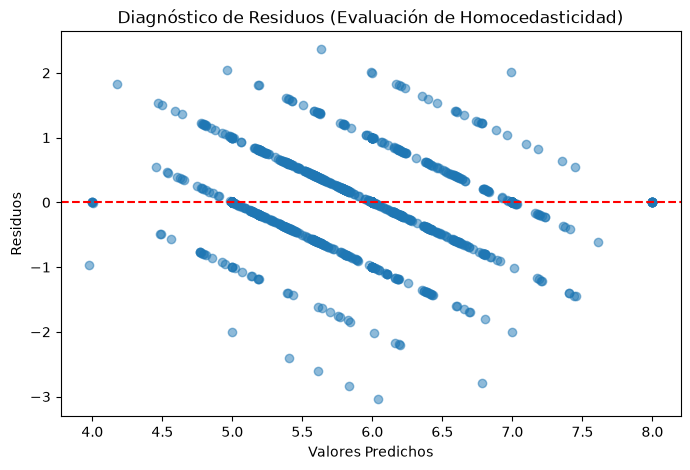

In [91]:
residuos = y_test - y_pred

# Gráfico de Residuos vs. Predicciones
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuos, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Valores Predichos")
plt.ylabel("Residuos")
plt.title("Diagnóstico de Residuos (Evaluación de Homocedasticidad)")
plt.show()

- Homocedasticidad: Los residuos deben distribuirse aleatoriamente alrededor de 0 con dispersión constante a lo largo de todo el rango de $\hat{y}$.
- Patrones en forma de embudo: Indican heterocedasticidad (la varianza del error aumenta con la magnitud de la predicción), sugiriendo la necesidad de aplicar una transformación logarítmica a la variable respuesta ($\log(y)$).

### Ideas Clave
- Elección $MAE$ vs. $RMSE$: Usar $MAE$ si el dominio tolera pequeños errores por igual; usar $RMSE$ si los errores grandes conllevan penalizaciones severas.
- Interpretación del $R^2$: Un $R^2 = 0.85$ indica que el modelo explica el $85\%$ de la variabilidad de los datos. Un $R^2 < 0$ indica que el modelo rinde peor que predecir la constante media $\bar{y}$.
- Cuidado con $MAPE$: Si la variable $y$ contiene ceros o valores numéricos muy reducidos, $MAPE$ tenderá a infinito o dará valores inestables.
___

## Optimización de Hiperparámetros, Transformación de la Variable Respuesta y TransformedTargetRegressor

### Objetivos

Al finalizar este apartado serás capaz de:

* Adaptar la búsqueda sistemática de hiperparámetros a problemas de regresión utilizando métricas explícitas de pérdida continua.
* Comprender el impacto de las distribuciones asimétricas (skewed target) en el aprendizaje de modelos de regresión.
* Implementar TransformedTargetRegressor para transformar la variable objetivo $y$ de forma segura y automatizar su inversión en las predicciones.

**Optimización Sistemática de Hiperparámetros en Regresión**

Al igual que en clasificación, los modelos de regresión poseen hiperparámetros críticos (ej. $\alpha$ en Ridge/Lasso, $C$ y $\epsilon$ en $SVR$, o max_depth en Random Forest).

**Métrica de Evaluación (scoring) en Scikit-Learn**

Scikit-Learn sigue la convención de que mayor es siempre mejor. Por ello, las métricas de error (como $MSE$ o $MAE$) se expresan como valores negativos:

- "neg_mean_squared_error"
- "neg_root_mean_squared_error"
- "neg_mean_absolute_error"
- "r2" (este se mantiene positivo)

In [92]:
# 1. Pipeline base
pipe_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", SVR())
])

# 2. Rejilla de hiperparámetros (sintaxis paso__parametro)
param_grid = {
    "regressor__C": [0.1, 1.0, 10.0],
    "regressor__epsilon": [0.01, 0.1, 0.2],
    "regressor__kernel": ["rbf", "linear"]
}

# 3. K-Fold estándar para regresión
cv_regresion = KFold(n_splits=5, shuffle=True, random_state=42)

# 4. GridSearchCV optimizando por RMSE (neg_root_mean_squared_error)
grid_svr = GridSearchCV(
    estimator=pipe_svr,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_regresion,
    n_jobs=-1
)

grid_svr.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_svr.best_params_}")
print(f"Mejor RMSE (CV): {-grid_svr.best_score_:.4f}")

Mejores parámetros: {'regressor__C': 1.0, 'regressor__epsilon': 0.2, 'regressor__kernel': 'rbf'}
Mejor RMSE (CV): 0.6814


### Transformación de la Variable Respuesta ($y$)

Cuando la variable respuesta $y$ presenta una fuerte asimetría positiva (right-skewness), los modelos basados en mínimos cuadrados y distancias sufren distorsiones graves por el peso desproporcionado de la cola superior.

Aplicar una transformación logarítmica $\log(1 + y)$ estabiliza la varianza y aproxima la variable a una distribución normal.

**El Riesgo de Fuga y Error de Inversión Manual**

Si transformamos $y$ manualmente antes de entrenar, debemos recordar aplicar la función inversa ($\exp(\hat{y}) - 1$) a todas las predicciones antes de calcular métricas de evaluación o presentarlas al usuario. Hacer esto manualmente en validación cruzada suele generar errores metodológicos.

### Automatización Limpia con TransformedTargetRegressor

TransformedTargetRegressor es un meta-estimador de Scikit-Learn que envuelve cualquier regresor o Pipeline y gestiona automáticamente:

- La transformación de $y$ antes del entrenamiento (fit).
- La destransformación/inversión de $\hat{y}$ al realizar predicciones (predict).

In [93]:
# 1. Definir el regresor base o Pipeline
regresor_base = HistGradientBoostingRegressor(random_state=42)

# 2. Envolver el modelo especificando la función y su inversa
modelo_transformado = TransformedTargetRegressor(
    regressor=regresor_base,
    func=np.log1p,       # Aplica log(1 + y) al entrenar
    inverse_func=np.expm1  # Aplica exp(y) - 1 al predecir
)

# 3. Entrenamiento: entrena sobre log1p(y_train) internamente
modelo_transformado.fit(X_train, y_train)

# 4. Predicción: predict(X_test) devuelve los valores directamente en la escala ORIGINAL de y
y_pred_original_scale = modelo_transformado.predict(X_test)

### Ideas Clave

- Signo negativo en métricas de CV: Al inspeccionar best_score_ en un GridSearchCV configurado con "neg_root_mean_squared_error" o "neg_mean_absolute_error", se debe anteponer el signo menos (-grid.best_score_) para obtener el valor de error positivo real.
- TransformedTargetRegressor dentro de GridSearch: Se puede pasar TransformedTargetRegressor directamente a un GridSearchCV, lo que garantiza que las métricas de validación cruzada se midan en la escala original de la variable objetivo $y$.
- Uso de func=np.log1p: Se prefiere np.log1p sobre np.log para prevenir errores de división por cero o logaritmos de números nulos cuando $y$ contiene ceros.
___